# Notebook dedicated to construct 3D Plots to illustrate the hit Type distribution

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob 
import plotly.graph_objects as go

# Load the Data

In [2]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/resume_npz/'
flist = sorted(glob.glob(fdir + 'e_*MeV_resumed.npz'))

observable_list = ['pmt_db', 'mcid', 'energy_mc', 'pos_mc', 'time_residual_recons', 'hit_type', 'hit_pmt_id', 'dir_mc']

data_dict = {obs_i: [] for obs_i in observable_list}

for file_i in flist:
    np_data = np.load(file_i)

    for obs_i in observable_list:
        data_dict[obs_i].append(np_data[obs_i])

for obs_i in observable_list:
    data_dict[obs_i] = np.concatenate(data_dict[obs_i], axis = 0)

print(data_dict['mcid'].shape)

(14809556,)


## Extract PMT Data Base

The PMT DB is structured as follows: (pmt_id, pos.x, pos.y, pos.z, pmt_type)

In [3]:
pmt_db = data_dict['pmt_db']
pmt_db_id = pmt_db[:,0]
pmt_db_pos_xyz = pmt_db[:,1:4]
pmt_db_type = pmt_db[:,4]

# Data Cuts

1) Apply data cuts
2) Separate hit types

In [4]:
# ========= Data Cuts =========
tres_inf, tres_sup = -4, 20
tres_mask = (data_dict['time_residual_recons'] >= tres_inf) & (data_dict['time_residual_recons'] <= tres_sup)

hit_cher_mask = (data_dict['hit_type'] == 1) # Select Cherenkov Hits 

general_mask = tres_mask & hit_cher_mask

# ========= Select the Data =========

mcid = data_dict['mcid'][general_mask]
energy_mc = data_dict['energy_mc'][general_mask]
pos_mc = data_dict['pos_mc'][general_mask]
hit_pmt_id = data_dict['hit_pmt_id'][general_mask]
dir_mc = data_dict['dir_mc'][general_mask]

hit_pmt_xyz = pmt_db_pos_xyz[hit_pmt_id]

In [5]:
# ========= Separate by events =========
event_start_indices = np.concatenate(([0], np.where(np.diff(mcid) != 0)[0] + 1)) # Array with the indices where an event start (event_start_indices[i]) and ends (event_start_indices[i+1]) 

hit_pmt_xyz_ev = np.split(hit_pmt_xyz, event_start_indices[1:])
hit_pmt_id_ev = np.split(hit_pmt_id, event_start_indices[1:])
energy_ev = energy_mc[event_start_indices]
pos_mc_ev = pos_mc[event_start_indices]
dir_mc_ev = dir_mc[event_start_indices]

# Plots

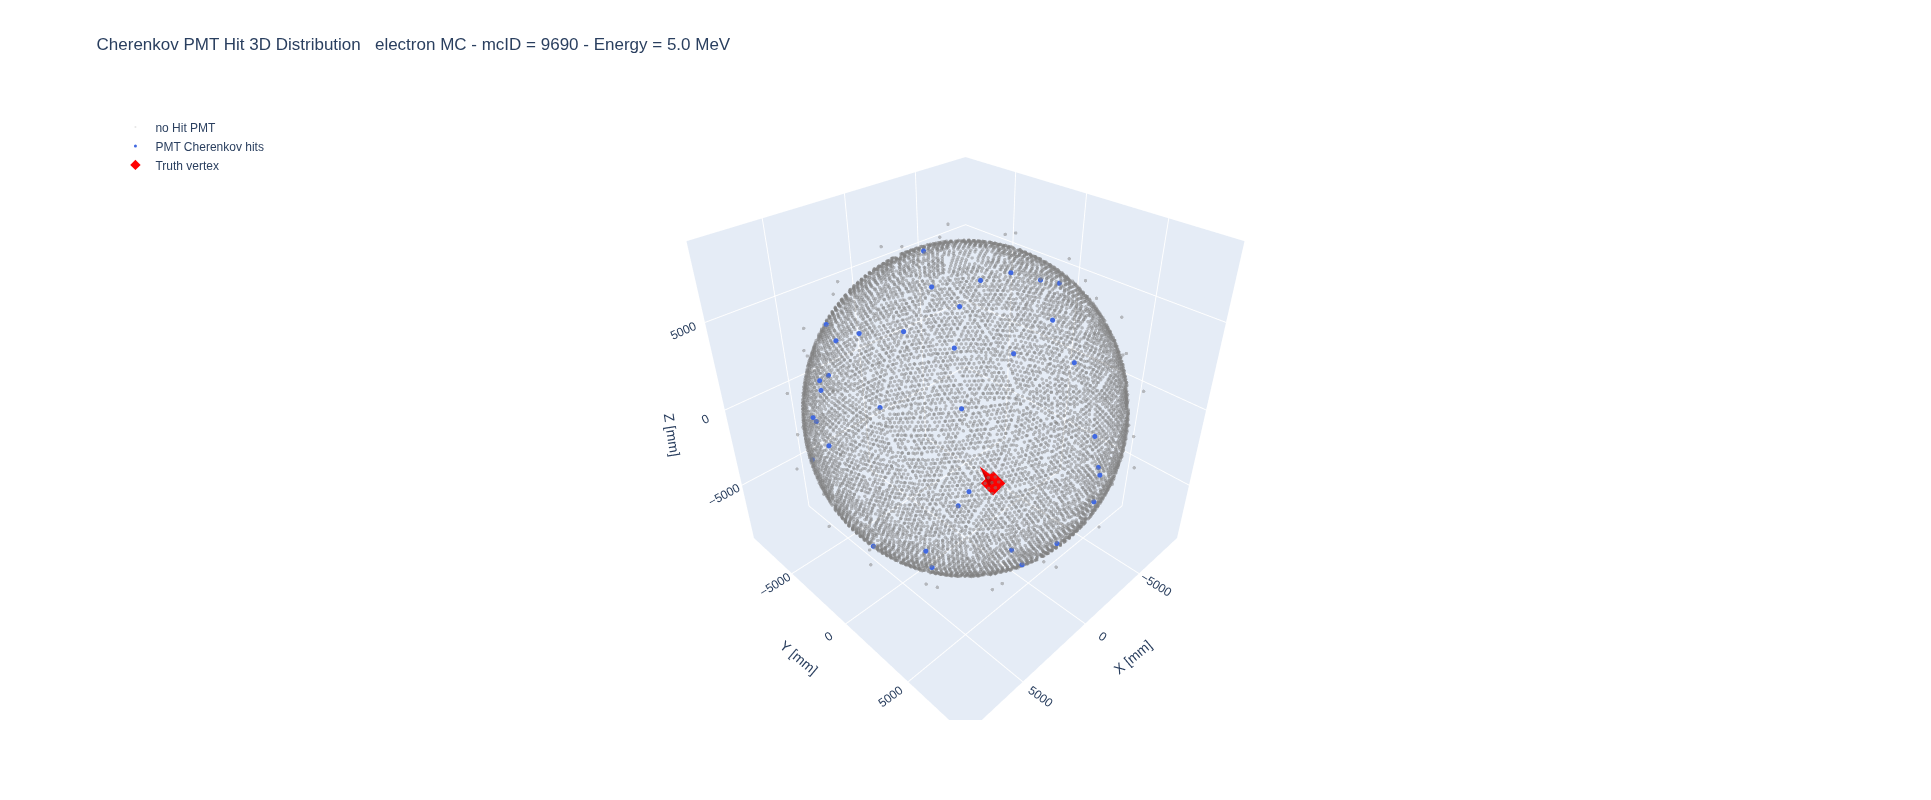

In [25]:
random_evtID = np.random.randint(0, len(energy_ev))  # Random number to pick a random event to plot
#random_evtID = 4383

# ======= Preparing the Data =======
hit_pmt_xyz_ev_i = hit_pmt_xyz_ev[random_evtID]
hit_pmt_id_ev_i = hit_pmt_id_ev[random_evtID]
energy_ev_i = energy_ev[random_evtID]
pos_mc_ev_i = pos_mc_ev[random_evtID]
dir_mc_ev_i = dir_mc_ev[random_evtID]

# Hit coordinates
x = hit_pmt_xyz_ev_i[:, 0]
y = hit_pmt_xyz_ev_i[:, 1]
z = hit_pmt_xyz_ev_i[:, 2]

# PMT DB coordinates: Remove PMT Type 2

no_hit_mask = ~np.isin(pmt_db_id, np.unique(hit_pmt_id_ev_i))
no_hit_xyz = pmt_db_pos_xyz[no_hit_mask]

# Vertex coordinates
vx, vy, vz = pos_mc_ev_i

# Vector Direction
arrow_length = 1000  # representative lenght for visualization
dx, dy, dz = dir_mc_ev_i *arrow_length

# ====== Figure ======
fig = go.Figure()

# PMTs without hits
fig.add_trace(go.Scatter3d(x=no_hit_xyz[:, 0], y=no_hit_xyz[:, 1], z=no_hit_xyz[:, 2], mode='markers', name = 'no Hit PMT',
                           marker=dict(size=2, opacity=0.2, color='gray'),hoverinfo='skip'))

# Hit PMT
fig.add_trace(go.Scatter3d(x=x, y=y, z=z,mode='markers',name='PMT Cherenkov hits',
        marker=dict(size=3,opacity=1,color='royalblue'),
        hovertemplate='X: %{x:.2f}<br>' +'Y: %{y:.2f}<br>' +'Z: %{z:.2f}<extra>PMT hit</extra>'))

# Event vertex
fig.add_trace(go.Scatter3d(x=[vx], y=[vy], z=[vz], mode='markers', name='Truth vertex', 
                           marker=dict(size=8,color='red',symbol='diamond')))

# Direction vector
fig.add_trace(go.Cone(x=[vx], y=[vy], z=[vz], u=[dx], v=[dy], w=[dz], name='Truth direction',
    colorscale=[[0, 'red'], [1, 'red']], showscale=False, sizemode='absolute', sizeref=arrow_length, anchor='tail'))

# Layout
fig.update_layout(title=f'Cherenkov PMT Hit 3D Distribution \n electron MC - mcID = {random_evtID} - Energy = {energy_ev_i} MeV', 
                  scene=dict(xaxis_title='X [mm]', xaxis = dict(nticks=4, range=[-9000, 9000]),
                             yaxis_title='Y [mm]', yaxis = dict(nticks=4, range=[-9000, 9000]),
                             zaxis_title='Z [mm]', zaxis = dict(nticks=4, range=[-9000, 9000]), aspectmode='data'), 
                  width=900, height=800, legend=dict(x=0.02,y=0.98),)

fig.show()